# ResNet50 + LGFFE: один новый эксперимент

ResNet50 **IMAGENET1K_V2**, 256×256, полный кадр. Последняя feature map → GAP и local branch с **GRU-based regional attention** → concat → 20 logits. Статья: [Lv et al., 2019, LGFFE](https://www.mdpi.com/2072-4292/11/24/3006); [детали реализации и отличия](../docs/lgffe_experiment.md).

Train: uniform random D4 (8 точных перестановок пикселей), остальные stronger domain_shift аугментации прежние. Ordinary CE, partial layer3+layer4, frozen backbone BN, 3 warmup-эпохи для всей новой головы. AdamW и cosine LR взяты из stronger50, 25 эпох, seed42.

**Запуск по умолчанию выключен.** Обучение рассчитано на Kaggle GPU. Val используется только для оценки, test не читается. После обучения сохраняются best.pt/last.pt, history.csv, графики, val_probabilities.npz и одна запись experiments.csv.

Это сравнение двух изменений сразу: LGFFE + геометрия D4 против stronger50 с H/V flips. По одному запуску нельзя приписать весь эффект только архитектуре. Результаты статьи на оригинальном RESISC45 не являются ожидаемым score нашего поднабора/искажённых split.


In [1]:
from pathlib import Path
import sys
import json
import torch
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src/experiment.py').is_file():
    raise RuntimeError('Откройте notebook из корня проекта или notebooks/')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.experiment import load_config, run_experiment
from src.models.lgffe_checks import check_lgffe
from src.training.predict import load_probabilities
from src.utils import get_device, plot_history


## Настройки

Для Kaggle укажите `RAW_DIR`, если изображения лежат отдельно от проекта. Для запуска измените только `RUN_TRAINING=True`; перед ним выполнится synthetic preflight. `DEVICE="auto"` выбирает GPU при наличии. На CPU предусмотрена безопасная проверка, но полный training run будет значительно медленнее. При нехватке памяти уменьшите BATCH_SIZE до первого запуска.


In [2]:
CONFIG = 'configs/resnet50_lgffe_domain_shift_stronger.json'
EXP_ID = 'resnet50_lgffe_domain_shift_stronger_001'
DEVICE = 'auto'
BATCH_SIZE = 32
NUM_WORKERS = 2 if get_device(DEVICE).type == 'cuda' else 0
CPU_THREADS = 4
RAW_DIR = PROJECT_ROOT / 'data/raw'  # либо Path('/kaggle/input/<dataset>')
RUN_PREFLIGHT = True
RUN_TRAINING = False

if get_device(DEVICE).type == 'cpu':
    torch.set_num_threads(CPU_THREADS)
config = load_config(CONFIG, project_root=PROJECT_ROOT)
config['data'].update(raw_dir=str(RAW_DIR), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
config['training']['device'] = DEVICE
print(f'{EXP_ID} | device={get_device(DEVICE)} | batch_size={BATCH_SIZE}')
print('train only; val evaluation; no test inference')


resnet50_lgffe_domain_shift_stronger_001 | device=cpu | batch_size=32
train only; val evaluation; no test inference


## Synthetic preflight

Проверяется настоящая torchvision ResNet50 с двумя синтетическими изображениями: shapes, сумма attention weights, градиенты GRU/attention, warmup, partial fine-tuning, BN buffers и LR groups. Это две synthetic optimizer steps, без данных и без скачивания ImageNet weights. Сам training run отдельно загрузит V2 weights (нужен интернет либо заранее подготовленный torch cache).


In [4]:
preflight = None
if RUN_PREFLIGHT or RUN_TRAINING:
    preflight = check_lgffe(config, device=DEVICE)
    print(json.dumps(preflight, indent=2, ensure_ascii=False))
else:
    print('Synthetic preflight выключен; обучение также выключено.')


{
  "device": "cpu",
  "torch": "2.14.1+cpu",
  "shapes": {
    "logits": [
      2,
      20
    ],
    "feature_map": [
      2,
      2048,
      8,
      8
    ],
    "regions": [
      2,
      64,
      2048
    ],
    "contextual_regions": [
      2,
      64,
      512
    ],
    "attention": [
      2,
      64
    ],
    "global_features": [
      2,
      2048
    ],
    "local_features": [
      2,
      2048
    ],
    "fused_features": [
      2,
      4096
    ]
  },
  "attention_normalized": true,
  "gru_and_attention_gradients": true,
  "warmup_head_updated": true,
  "partial_layer3_layer4_updated": true,
  "early_backbone_unchanged": true,
  "bn_buffers_unchanged": true,
  "optimizer_groups_stable": true,
  "pretrained_downloaded": false,
  "parameters": 29556885,
  "optimizer_lrs": {
    "backbone": 5e-05,
    "head": 0.0005
  },
  "elapsed_seconds": 2.8017868000024464
}


## Один training run

Новый `exp_id` не перезаписывает предыдущие эксперименты. Если run с этим ID уже существует, pipeline остановится: для нового обучения требуется другой ID. Для просмотра уже завершённого запуска оставьте `RUN_TRAINING=False`.


In [6]:
result = None
if RUN_TRAINING:
    assert preflight is not None
    result = run_experiment(config, exp_id=EXP_ID, project_root=PROJECT_ROOT,
                            show_plots=True, predict_test=False)
else:
    print('Обучение выключено. Для запуска на Kaggle установите RUN_TRAINING=True.')


Обучение выключено. Для запуска на Kaggle установите RUN_TRAINING=True.


## Короткий результат и сравнение с stronger50

Сравнение Accuracy и ошибок на тех же val IDs, без TTA. Используется сохранённый лучший stronger50 `resnet50_partial_domain_shift_stronger_001`. Таблица показывает, сколько его ошибок исправлено и сколько новых появилось; public/test score здесь не оценивается.


,exp_id,best_epoch,val_accuracy,train_time_min
0,resnet50_lgffe_domain_shift_stronger_001,18,0.955651,18.898557


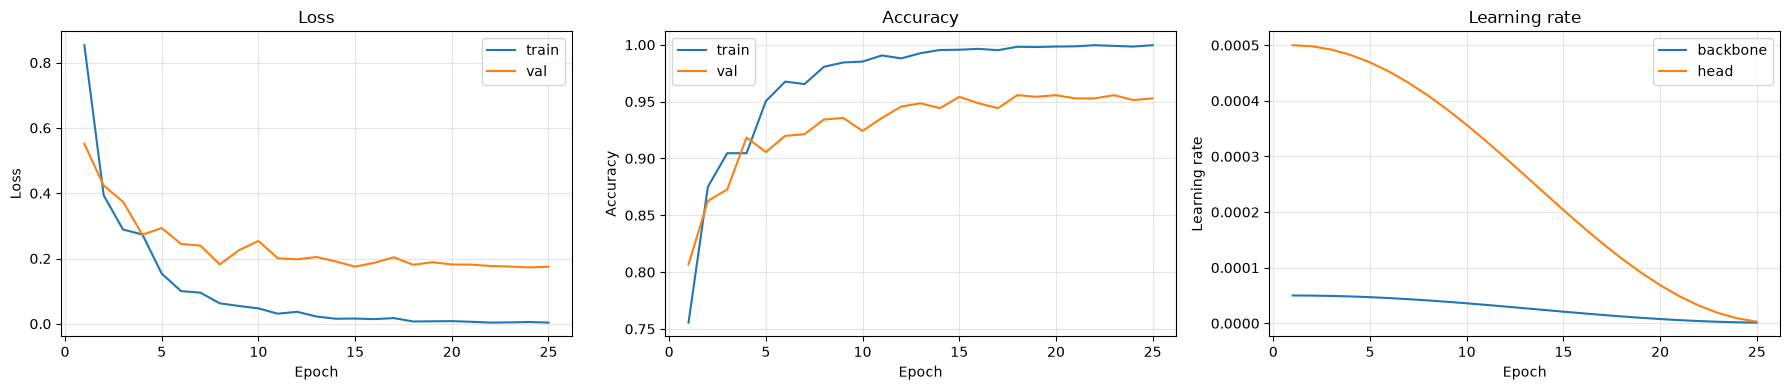

,model,correct,accuracy
0,stronger50 H/V,675,0.965665
1,LGFFE D4,668,0.955651


Исправлено: 6; новых ошибок: 13; общих ошибок: 18


,id,true_label,stronger50_label,lgffe_label,stronger50_confidence,lgffe_confidence
2,45.jpg,5,3,5,0.650349,0.918069
64,1450.jpg,3,3,5,0.986378,0.689686
72,1617.jpg,6,19,6,0.899272,0.940002
76,1685.jpg,8,2,8,0.900393,0.569248
148,2988.jpg,9,9,17,0.685769,0.394001
175,3565.jpg,6,6,19,0.980653,0.756598
195,3986.jpg,10,10,11,0.883505,0.996492
252,5108.jpg,18,11,18,0.679817,0.991370
305,6146.jpg,11,9,8,0.966164,0.251803
311,6323.jpg,7,7,9,0.998859,0.496226


Веса: C:\Users\peret\Desktop\Third year\ML\comp\comp 2\artifacts\models\resnet50_lgffe_domain_shift_stronger_001
Логи и вероятности: C:\Users\peret\Desktop\Third year\ML\comp\comp 2\artifacts\logs\resnet50_lgffe_domain_shift_stronger_001 | C:\Users\peret\Desktop\Third year\ML\comp\comp 2\artifacts\predictions\resnet50_lgffe_domain_shift_stronger_001


In [7]:
logs = PROJECT_ROOT / 'artifacts/logs' / EXP_ID
predictions = PROJECT_ROOT / 'artifacts/predictions' / EXP_ID
summary_path = logs / 'summary.json'
if not summary_path.is_file():
    print('Результатов LGFFE ещё нет. После обучения выполните эту ячейку повторно.')
else:
    summary = json.loads(summary_path.read_text(encoding='utf-8'))
    display(pd.DataFrame([{'exp_id': EXP_ID, **summary}]))
    if result is None:
        plot_history(pd.read_csv(logs / 'history.csv'), show=True)
    candidate = load_probabilities(predictions / 'val_probabilities.npz').table(include_scores=True)
    baseline_path = PROJECT_ROOT / 'artifacts/predictions/resnet50_partial_domain_shift_stronger_001/val_probabilities.npz'
    if baseline_path.is_file():
        baseline = load_probabilities(baseline_path).table(include_scores=True)
        baseline = baseline.set_index('id').reindex(candidate.id).reset_index()
        if baseline.label.isna().any() or len(baseline) != len(candidate):
            raise ValueError('Baseline/candidate val IDs не совпадают')
        if not (baseline.true_label.to_numpy() == candidate.true_label.to_numpy()).all():
            raise ValueError('Baseline/candidate val targets не совпадают')
        old_ok = baseline.label.to_numpy() == baseline.true_label.to_numpy()
        new_ok = candidate.label.to_numpy() == candidate.true_label.to_numpy()
        display(pd.DataFrame([
            {'model': 'stronger50 H/V', 'correct': int(old_ok.sum()), 'accuracy': float(old_ok.mean())},
            {'model': 'LGFFE D4', 'correct': int(new_ok.sum()), 'accuracy': float(new_ok.mean())},
        ]))
        print(f'Исправлено: {int((~old_ok & new_ok).sum())}; новых ошибок: {int((old_ok & ~new_ok).sum())}; '
              f'общих ошибок: {int((~old_ok & ~new_ok).sum())}')
        changed = pd.DataFrame({'id': candidate.id, 'true_label': candidate.true_label,
                               'stronger50_label': baseline.label, 'lgffe_label': candidate.label,
                               'stronger50_confidence': baseline.confidence, 'lgffe_confidence': candidate.confidence})
        display(changed[changed.stronger50_label != changed.lgffe_label].head(30))
    else:
        print('Baseline val_probabilities.npz отсутствует; сохранённый результат LGFFE показан выше.')
    print(f'Веса: {PROJECT_ROOT / "artifacts/models" / EXP_ID}')
    print(f'Логи и вероятности: {logs} | {predictions}')
